In [1]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


Initial guess [-1.2, 1.2], Result: [0.99999557 0.99999114], Value: 1.9589240070153638e-11, Success: True, Iterations: 34, Time: 0.0141 sec
Initial guess [0.25, 2], Result: [0.99999553 0.99999105], Value: 2.0002084131538035e-11, Success: True, Iterations: 21, Time: 0.0100 sec
Initial guess [3, -0.2], Result: [0.99999559 0.99999117], Value: 1.94749009468531e-11, Success: True, Iterations: 42, Time: 0.0140 sec


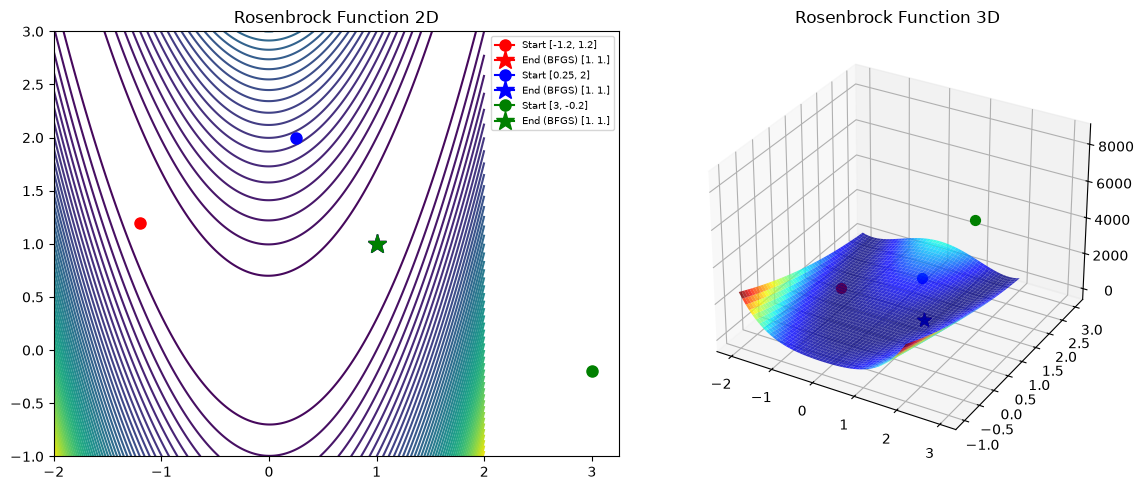

c:\Users\Kamal Singh\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1.2, 1.2], Solution: [0.96671625 0.93434898], Value: 0.0011114687625063933, iterations: 2000, Time: 1.4759 sec
PyGAD initial guess [0.25, 2], Solution: [1.0170761  1.03418356], Value: 0.0002983646257240983, iterations: 2000, Time: 1.2606 sec
PyGAD initial guess [3, -0.2], Solution: [0.97096848 0.94320881], Value: 0.0008612351745000595, iterations: 2000, Time: 1.2103 sec


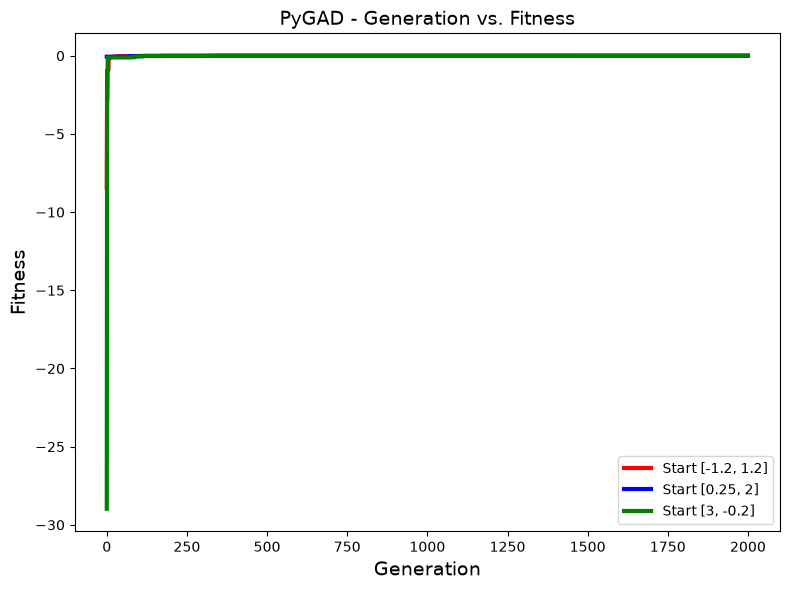

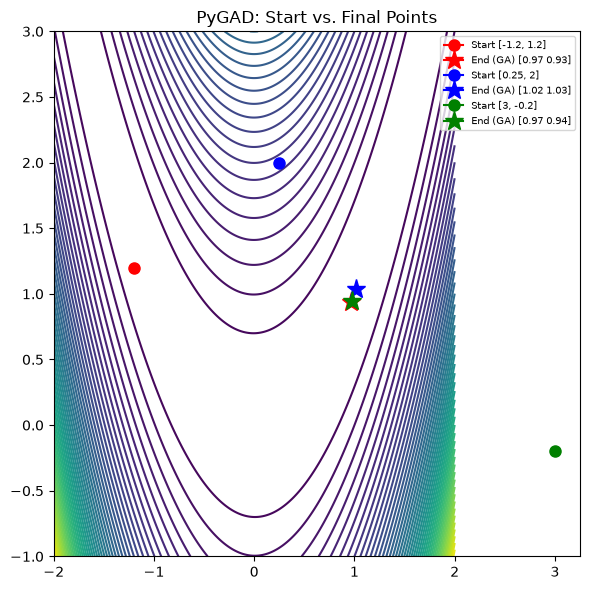

In [5]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")

init_guesses = [[-1.2, 1.2], [0.25, 2], [3, -0.2]]
colors = ['red', 'blue', 'green']

# ------------------- Scipy Optimization -------------------
scipy_results = []  # store (guess, final_point, color) for plotting later

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed:.4f} sec")

    scipy_results.append((guess, result.x, color))

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface (offset slightly in z for visibility)
    ax2.scatter(guess[0], guess[1], rosenbrock(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], rosenbrock(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                            sol_per_pop=20,
                            num_genes=2,
                            num_parents_mating=8,
                            fitness_func=fitness_func,
                            init_range_low=-2,
                            init_range_high=2,
                            gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    final_value = rosenbrock(solution)
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {final_value}, "
          f"iterations: {iters}, Time: {elapsed:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    # keep it as fitness (not converted to rosenbrock value) to match PyGAD's default plot style
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

Problem 1 – Rosenbrock Function

f(x,y)=(1−x)^2+100(y−x^2)^2

 SciPy:
The BFGS method converged to \((1,1)\), where the function value is 0. Different initial guesses gave the same solution. Hence, the solution is the global minimum.

 Genetic Algorithm:
The genetic algorithm also reached approximately \((1,1)\). Small differences may occur because GA is a random method. It also found the global minimum.

 Comparison:
BFGS was faster and required fewer iterations, while GA required more generations. Therefore, BFGS performed better for this problem.

Initial guess [3, -2], Result: [ 1.00000001e+00 -5.91763219e-08], Value: 4.3542183907886616e-15, Success: True, Iterations: 14, Time: 0.0032 sec
Initial guess [2.2, -0.6], Result: [ 1.00000006e+00 -1.86374010e-06], Value: 3.4926055403335608e-12, Success: True, Iterations: 11, Time: 0.0033 sec
Initial guess [3, -0.2], Result: [ 1.00000003e+00 -9.68079336e-09], Value: 3.848936652257308e-15, Success: True, Iterations: 14, Time: 0.0031 sec


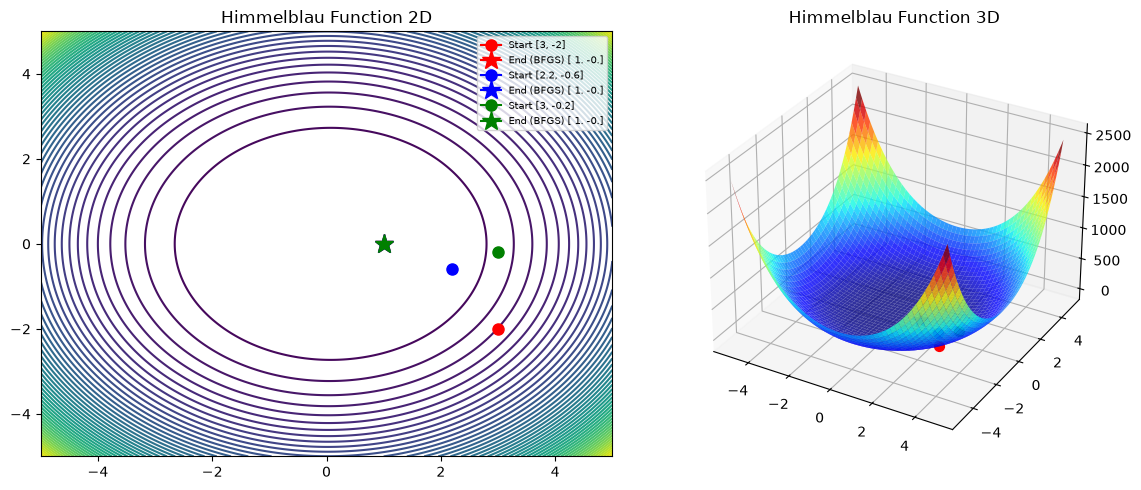

c:\Users\Kamal Singh\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [3, -2], Solution: [0.99172262 0.00451979], Value: 0.0003600668687196378, iterations: 300, Time: 0.3607 sec
PyGAD initial guess [2.2, -0.6], Solution: [0.98387157 0.00464508], Value: 0.0013041134768427862, iterations: 300, Time: 0.2277 sec
PyGAD initial guess [3, -0.2], Solution: [ 0.99646402 -0.00157756], Value: 6.47927721567985e-05, iterations: 300, Time: 0.2733 sec


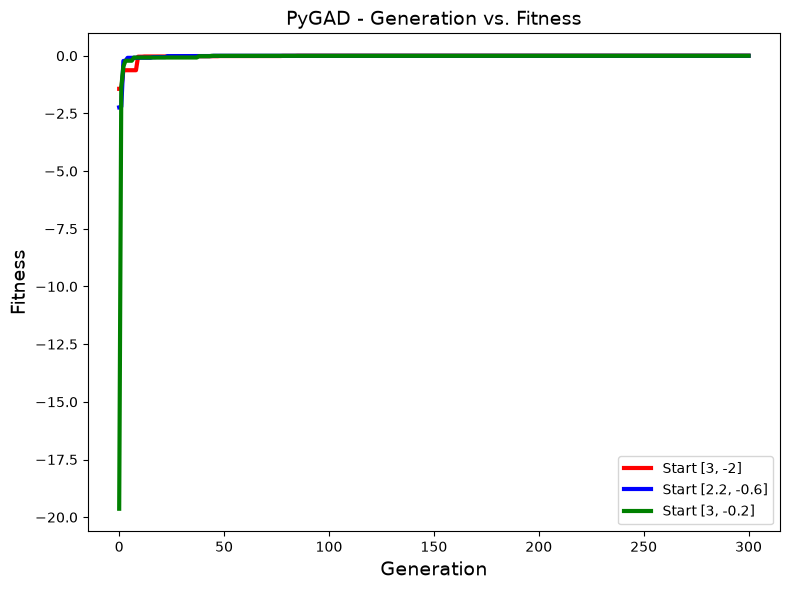

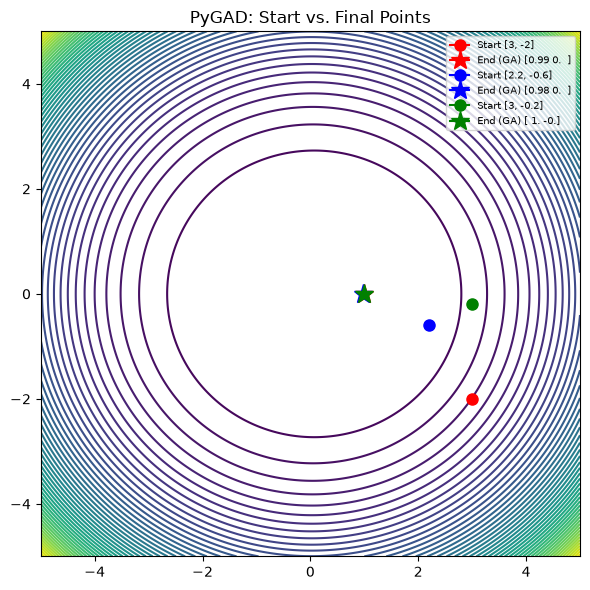

In [7]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

def himmelblau(x):
    x = np.asarray(x)  # Convert to numpy array
    return ((x[0]**2 + x[1]**2 - 1)**2 + (x[0]-1)**2 + x[1]**2)

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")

init_guesses = [[3, -2], [2.2, -0.6], [3, -0.2]]
colors = ['red', 'blue', 'green']

# ------------------- Scipy Optimization -------------------
for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = -start_time + end_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface
    ax2.scatter(guess[0], guess[1], himmelblau(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], himmelblau(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                            sol_per_pop=30,
                            num_genes=2,
                            num_parents_mating=12,
                            fitness_func=fitness_func2,
                            init_range_low=-5,
                            init_range_high=5,
                            gene_space={'low': -5, 'high': 5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = -start_time + end_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

Problem 2
f(x,y)=(x^2+y^2−1)^2+(x−1)^2+y^2

 SciPy:
The BFGS method converged to \((1,0)\), where the function value is 0. The same solution was obtained from different initial guesses. Therefore, it is the global minimum.

 Genetic Algorithm:
The genetic algorithm also approached \((1,0)\). The small variation in results is due to the random nature of GA. It successfully found the global minimum.

 Comparison:
BFGS was faster and used fewer iterations, while GA needed more generations. Hence, BFGS was more efficient for this problem.